# Fine-tuning a VLA: full, LoRA, OFT, or a frozen backbone? 🔧
### Learning a new skill without forgetting the old ones, step by step

**Code:** `src/Halo_VLA/vla_foundations/finetuning.py` (`LoRALinear`, `OFTLinear`, `inject_adapters`, `freeze_all_but`, `hyperspherical_energy`), `training.py` (`ReplayMixture`) ·
**papers:** LoRA ([arXiv:2106.09685](https://arxiv.org/abs/2106.09685)), Orthogonal Finetuning ([2306.07280](https://arxiv.org/abs/2306.07280)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)), OpenVLA-OFT ([2502.19645](https://arxiv.org/abs/2502.19645)), *LoRA Learns Less and Forgets Less* ([2405.09673](https://arxiv.org/abs/2405.09673)).

Every deployment of a VLA ends with the same step: take a pre-trained model and adapt it to *your* robot or task with a small amount of data. The question is **which weights to update**. This notebook builds the four standard options, verifies the mechanics by hand, and then
measures the trade-off that actually matters: **how much the model learns** versus **how much it forgets**.

| method | what is trained | extra parameters |
|---|---|---|
| **full fine-tuning** | every weight | none |
| **LoRA** | low-rank updates `B A` added to the attention projections | `r (in + out)` per matrix |
| **OFT** (orthogonal fine-tuning) | an orthogonal rotation of each attention projection | `blocks · b²` per matrix |
| **frozen backbone + head** | only the output layer (and its final norm) | none |

### Where this notebook corrects the usual summary
* **"OpenVLA-OFT" is *not* orthogonal fine-tuning.** OpenVLA-OFT (Kim et al., 2025, *Optimizing Speed and Success*) is an **optimised fine-tuning recipe**: parallel decoding with bidirectional attention, action chunking, a **continuous** action head trained with an **L1** regression loss, and optional FiLM conditioning. It was built to make fine-tuning OpenVLA much
  *faster* (26× higher action-generation throughput) and *more successful* (76.5 → 97.1 % average success on LIBERO, per the paper's abstract). **OFT as orthogonal fine-tuning** (Qiu et al., 2023) is a different method from the text-to-image literature that this notebook implements. They share only an acronym.
* "OFT generalises better than LoRA" is a hypothesis, not an established fact for robot policies. This notebook measures it at toy scale (Step 5) and finds that **the learning rate and whether you replay old data matter more than the choice of adapter**.
* LoRA in OpenVLA is applied to **all linear layers** (rank 32, ≈ 1.4 % of the parameters) and matches full fine-tuning on their tasks; our toy adapts only the attention projections.

| | published | this notebook |
|---|---|---|
| base model | OpenVLA 7B | 236K-parameter toy VLM (RT-2 style: the VLM *is* the policy) |
| adaptation data | 10-150 demonstrations of a new task / robot | 60 demonstrations of a colour the robot never targeted |
| what is measured | success on the new task | **new** colour, **old** colours, **synonym** instructions, **VQA** ability |

## Step 0: The pre-trained policy we will adapt

We reuse the RT-2-style policy of the other notebooks (the VLM emits the action tokens). Its **pre-training** has two stages: the VLM learns visual question answering (with synonyms: "crimson" = red), then it is **co-fine-tuned** on robot demonstrations whose *target* is always red or green
(blue appears only as a distractor). We then want to teach it "go to blue" from a few demonstrations, and to know afterwards (a) can it do it? (b) can it still do red and green? (c) does it still follow "go to crimson"? (d) can it still answer questions?

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots

from open_vlas import EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, ToyVLM, VLMConfig, VLMPretrainer
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.autoregressive import ARConfig, AutoregressiveActionPolicy, make_cofine_tune_data
from vla_foundations.finetuning import (LoRALinear, OFTLinear, count_parameters, freeze_all_but, hyperspherical_energy, inject_adapters)
from vla_foundations.tasks import colour_demos, colour_scenarios
from vla_foundations.training import ReplayMixture

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld(); gen = DemoGenerator(world); vocab = PiVocabulary(fast_size=256)
vlm = ToyVLM(VLMConfig(width=64, depth=4, num_heads=4, head_dim=16), vocab)
pre = VLMPretrainer(vlm, world, synonym_prob=0.3); pre.fit(1500)
print(f"VLM pre-trained on VQA (with synonyms) in {pre.history.seconds:.0f} s, answer accuracy {np.mean(pre.history.accuracy[-50:]):.2f}")

src_demos = colour_demos(gen, 4000, np.random.default_rng(0), ("red", "green"))
src_data = EmbodiedMixture([EmbodiedSource(world, src_demos, EMBODIMENTS["point2d"], chunk_size=1)])
blue_demos = colour_demos(gen, 60, np.random.default_rng(5), ("blue",))
blue_data = EmbodiedMixture([EmbodiedSource(world, blue_demos, EMBODIMENTS["point2d"], chunk_size=1)])
ev = EmbodiedEvaluator(world, 1, 1, 50)
scenarios = {"old colours": colour_scenarios(gen, 96, 1, ("red", "green")), "new colour (blue)": colour_scenarios(gen, 96, 2, ("blue",)),
             "old, via synonym": colour_scenarios(gen, 96, 3, ("red", "green"), synonyms=True)}
vqa_images, vqa_questions, vqa_answers = VLMPretrainer(vlm, world, synonym_prob=0.3, seed=77).sample(256)

def vqa_accuracy(policy):
    v = policy.vocab
    return policy._ce(vqa_images, vqa_questions, [v.encode(a) + [v["<eos>"]] for a in vqa_answers])[1]

def evaluate(policy):
    policy.eval()
    out = {k: ev.run(lambda b: policy.sample_actions(b), s).success_rate for k, s in scenarios.items()}
    out["VQA accuracy"] = vqa_accuracy(policy)
    return out

torch.manual_seed(0)
source = AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=1))
sampler = VLMPretrainer(vlm, world, synonym_prob=0.3, seed=5).sample
tr = PiTrainer(source, make_cofine_tune_data(src_data, sampler, 0.5), batch_size=64, grad_clip=10.0); tr.fit(3000)
base = evaluate(source)
print(f"source policy trained in {tr.history.seconds:.0f} s:", {k: round(v, 2) for k, v in base.items()})

VLM pre-trained on VQA (with synonyms) in 116 s, answer accuracy 0.93


source policy trained in 467 s: {'old colours': 0.93, 'new colour (blue)': 0.02, 'old, via synonym': 0.83, 'VQA accuracy': 0.94}


The source policy follows red and green (and their synonyms) and answers questions well, but is **poor at blue** (it has seen the word and the colour only in VQA, never as a target of an action). That is the gap fine-tuning has to close.

# Part 1: The mechanics, by hand

## Step 1: LoRA: a low-rank update

Take a frozen weight `W ∈ ℝ^{out×in}`. LoRA learns a **low-rank correction**:
$$h = W x + \tfrac{\alpha}{r}\, B A x,\qquad A\in\mathbb R^{r\times in},\; B\in\mathbb R^{out\times r},\; r \ll \min(in, out).$$
`A` is initialised randomly, **`B = 0`**, so the adapter starts as the identity (the model is unchanged at step 0). Trainable parameters per matrix: `r (in + out)` instead of `in · out`. After training the update can be **merged**: `W' = W + (α/r) B A`, so inference has no extra cost.
We verify each property on a real attention matrix of our VLM.

In [2]:
W = source.vlm.layers[0].q                      # a real attention projection (64 × 64)
x = torch.randn(5, W.in_features)
lora = LoRALinear(copy.deepcopy(W), rank=4, alpha=8.0)
print("starts as the identity (B = 0):", torch.allclose(lora(x), W(x)))
with torch.no_grad():
    lora.lora_b.normal_(0, 0.1)
print("merged weight reproduces the adapter's output:", torch.allclose(lora(x), x @ lora.merged_weight().T + (W.bias if W.bias is not None else 0), atol=1e-5))
rank = int(torch.linalg.matrix_rank(lora.delta_weight(), atol=1e-5))
print(f"rank of the update ΔW: {rank} (≤ r = {lora.rank}) | trainable {lora.lora_a.numel() + lora.lora_b.numel()} of {W.weight.numel()} parameters ({(lora.lora_a.numel() + lora.lora_b.numel()) / W.weight.numel():.1%})")
sv = torch.linalg.svdvals(lora.delta_weight())
print("singular values of ΔW:", sv[:8].round(decimals=3).tolist())

starts as the identity (B = 0): True
merged weight reproduces the adapter's output: True
rank of the update ΔW: 4 (≤ r = 4) | trainable 512 of 4096 parameters (12.5%)
singular values of ΔW: [2.572999954223633, 1.9179999828338623, 1.684999942779541, 1.4420000314712524, 0.0, 0.0, 0.0, 0.0]


## Step 2: OFT: a rotation instead of an addition

**Orthogonal fine-tuning** (Qiu et al., 2023) changes the weight *multiplicatively*: it keeps `W` frozen and learns an **orthogonal** matrix `R`, so that `W' = W R` (here `R` acts on the layer's input; the neurons are the rows of `W`). A rotation preserves lengths and angles, so the **pairwise angles between the neurons cannot change**, which is
the *hyperspherical energy* (`HE = mean_{i<j} 1/‖ŵ_i − ŵ_j‖`) of the layer. The authors argue that this retains the pre-trained model's "semantic structure", and observe that the weights of a pre-trained model are tuned to specific angles.

`R` is block-diagonal (`k` blocks of size `b`) to keep the parameter count down, and each block is parametrised with the **Cayley transform** of a skew-symmetric matrix `Q = A − Aᵀ`:
$$R = (I + Q)(I - Q)^{-1}\quad\Rightarrow\quad R R^{\top} = I \text{ for every } A,\qquad R = I \text{ when } A = 0 .$$
Orthogonality is therefore *exact by construction*, with no penalty term. We verify it, and compare the neuron-angle structure after OFT, LoRA and a random full update of the same size.

starts as the identity (R = I): True
max |R Rᵀ − I| over all blocks: 3.5762786865234375e-07
merged weight W R reproduces the layer: True
hyperspherical energy: original 0.7546 | OFT (random large rotation) 0.7546 | LoRA (random large update) 0.7728 | full (general linear update) 0.7509


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_71542/824633999.py:8: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  print("max |R Rᵀ − I| over all blocks:", float((R @ R.transpose(-1, -2) - torch.eye(8)).abs().max()))


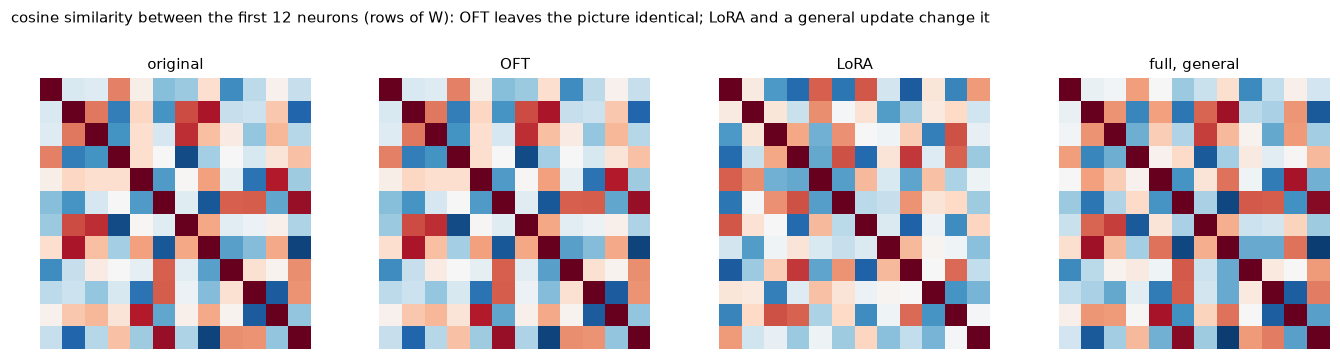

In [3]:
W = source.vlm.layers[0].q
oft = OFTLinear(copy.deepcopy(W), block_size=8)
x = torch.randn(5, W.in_features)
print("starts as the identity (R = I):", torch.allclose(oft(x), W(x), atol=1e-6))
with torch.no_grad():
    oft.skew.normal_(0, 0.4)                      # a large random 'update'
R = oft.rotation()
print("max |R Rᵀ − I| over all blocks:", float((R @ R.transpose(-1, -2) - torch.eye(8)).abs().max()))
print("merged weight W R reproduces the layer:", torch.allclose(oft(x), x @ oft.merged_weight().T, atol=1e-5))
he0 = hyperspherical_energy(W.weight)
with torch.no_grad():
    lora.lora_b.normal_(0, 0.3)
w_lora = lora.merged_weight()
w_full = W.weight.detach() @ (torch.eye(W.in_features) + 0.3 * torch.randn(W.in_features, W.in_features))   # a general (non-orthogonal) mixing of the inputs
print(f"hyperspherical energy: original {he0:.4f} | OFT (random large rotation) {hyperspherical_energy(oft.merged_weight()):.4f} | LoRA (random large update) {hyperspherical_energy(w_lora):.4f} | full (general linear update) {hyperspherical_energy(w_full):.4f}")

def cosines(w):
    n = torch.nn.functional.normalize(w.detach()[:12], dim=1)
    return (n @ n.T).numpy()
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.1))
for ax, (name, w) in zip(axes, (("original", W.weight), ("OFT", oft.merged_weight()), ("LoRA", w_lora), ("full, general", w_full))):
    ax.imshow(cosines(w), cmap="RdBu_r", vmin=-1, vmax=1); ax.set_title(name, fontsize=10); ax.axis("off")
plt.suptitle("cosine similarity between the first 12 neurons (rows of W): OFT leaves the picture identical; LoRA and a general update change it", x=0.01, ha="left", fontsize=10, y=1.04)
plt.tight_layout(); plt.show()

The OFT rotation changes the weights a lot (the rows point in new directions) yet leaves every **pairwise angle** and every **row norm** exactly as they were: the energy is the same to six digits and the similarity matrix is identical. LoRA and a general (non-orthogonal) full update change the angles.
Whether *keeping the angles* is what a robot policy needs is the empirical question of Part 2.

## Step 3: What each method trains

`inject_adapters` replaces the `q, k, v, o` projections of every transformer layer by LoRA / OFT wrappers (frozen base + adapter); `freeze_all_but` freezes everything except the parameters we name.

In [4]:
def make_model(method):
    m = copy.deepcopy(source)
    if method == "lora":
        inject_adapters(m.vlm, "lora", rank=4, alpha=8.0); freeze_all_but(m, lambda n: "lora_" in n)
    elif method == "oft":
        inject_adapters(m.vlm, "oft", block_size=8); freeze_all_but(m, lambda n: "skew" in n)
    elif method == "head":
        freeze_all_but(m, lambda n: "lm_head" in n or "final_norm" in n)
    return m
rows = {}
for method in ("full", "lora", "oft", "head"):
    rows[method] = count_parameters(make_model(method))
    print(f"{method:5s} trainable {rows[method]['trainable']:7,d} of {rows[method]['total']:7,d} parameters ({rows[method]['fraction']:.1%})")

full  trainable 235,968 of 235,968 parameters (100.0%)
lora  trainable   8,192 of 244,160 parameters (3.4%)
oft   trainable   8,192 of 244,160 parameters (3.4%)
head  trainable  19,904 of 235,968 parameters (8.4%)


# Part 2: Learning vs forgetting

## Step 4: Adapt to a new colour with 60 demonstrations

We adapt a copy of the source policy to `go to blue` with **60** demonstrations for 600 steps, with each method, **at three learning rates** (the learning rate is the most influential nuisance parameter in fine-tuning, so comparing methods at one arbitrary value would be misleading). The baseline `head` trains the output layer only. For each run we record the
success on the **new** colour, and what is **kept**: success on the old colours, on the old colours via synonyms, and the VQA accuracy.

In [5]:
results = {}
def adapt(method, lr, steps=600, data=blue_data):
    torch.manual_seed(0)
    m = make_model(method.split("+")[0])
    PiTrainer(m, data, batch_size=64, lr=lr, grad_clip=10.0).fit(steps)
    r = evaluate(m)
    results[(method, lr)] = r
    print(f"{method:12s} lr {lr:7.0e}: " + "  ".join(f"{k} {v:.2f}" for k, v in r.items()), flush=True)
    return m
adapted = {}
for method in ("full", "lora", "oft"):
    for lr in (2e-4, 5e-4, 2e-3):
        adapted[(method, lr)] = adapt(method, lr)
adapted[("head", 2e-3)] = adapt("head", 2e-3)

full         lr   2e-04: old colours 0.81  new colour (blue) 0.82  old, via synonym 0.83  VQA accuracy 0.94


full         lr   5e-04: old colours 0.76  new colour (blue) 0.78  old, via synonym 0.73  VQA accuracy 0.90


full         lr   2e-03: old colours 0.26  new colour (blue) 0.49  old, via synonym 0.12  VQA accuracy 0.35


lora         lr   2e-04: old colours 0.90  new colour (blue) 0.74  old, via synonym 0.83  VQA accuracy 0.94


lora         lr   5e-04: old colours 0.85  new colour (blue) 0.77  old, via synonym 0.75  VQA accuracy 0.93


lora         lr   2e-03: old colours 0.71  new colour (blue) 0.75  old, via synonym 0.57  VQA accuracy 0.82


oft          lr   2e-04: old colours 0.85  new colour (blue) 0.70  old, via synonym 0.82  VQA accuracy 0.93


oft          lr   5e-04: old colours 0.86  new colour (blue) 0.77  old, via synonym 0.79  VQA accuracy 0.92


oft          lr   2e-03: old colours 0.62  new colour (blue) 0.77  old, via synonym 0.42  VQA accuracy 0.80


head         lr   2e-03: old colours 0.76  new colour (blue) 0.07  old, via synonym 0.66  VQA accuracy 0.91


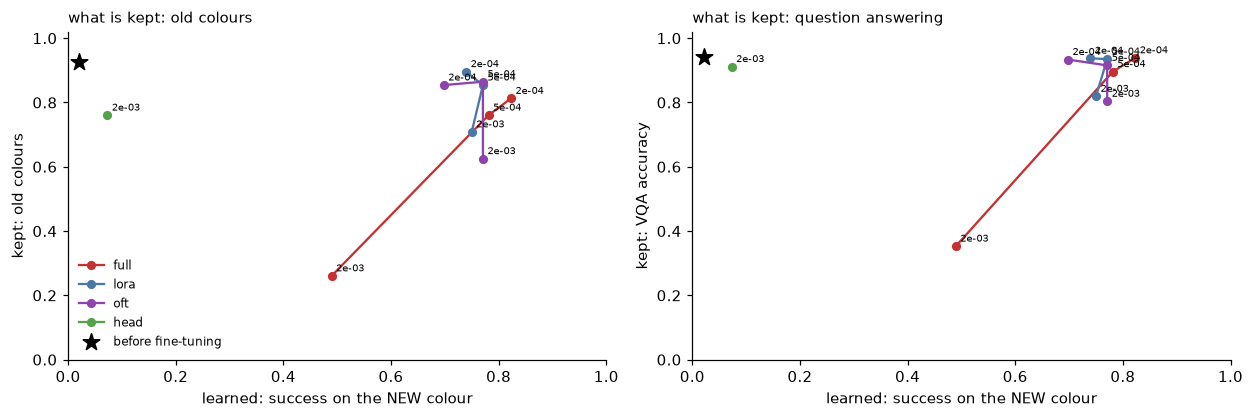

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
colours = {"full": "#c53030", "lora": "#4c78a8", "oft": "#8e44ad", "head": "#54a24b", "full+replay": "#f58518"}
for ax, keep, title in ((axes[0], "old colours", "what is kept: old colours"), (axes[1], "VQA accuracy", "what is kept: question answering")):
    for method in ("full", "lora", "oft", "head", "full+replay"):
        pts = sorted((k[1], v) for k, v in results.items() if k[0] == method)
        if not pts:
            continue
        xs, ys = [p[1]["new colour (blue)"] for p in pts], [p[1][keep] for p in pts]
        ax.plot(xs, ys, "o-", color=colours[method], label=method, ms=5)
        for (lr, _), x, y in zip(pts, xs, ys):
            ax.annotate(f"{lr:.0e}", (x, y), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
    ax.scatter([base["new colour (blue)"]], [base[keep]], marker="*", s=130, color="k", label="before fine-tuning", zorder=5)
    ax.set_xlabel("learned: success on the NEW colour"); ax.set_ylabel(f"kept: {keep}"); ax.set_title(title, fontsize=10, loc="left"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**How to read the plot.** Up and to the right is best (learn the new skill *and* keep the old ones); the star is the model before adaptation. Each line is one method swept over the learning rate (labels). **What the measurements say** (one seed, 96 scenes per number: ± 5-8 points is noise):

* **At a small learning rate (2e-4) the three methods learn the new colour** (blue 0.70-0.82, up from 0.02) and keep their question answering (VQA 0.93-0.94). The adapters keep slightly more of the old behaviour (old colours 0.85-0.90 vs 0.81 for full fine-tuning) and learn slightly less (0.70-0.74 vs 0.82): the "**LoRA learns less and forgets less**" pattern, but the differences are small.
* **At a medium learning rate (5e-4) they are practically indistinguishable** (blue ≈ 0.77-0.78, old colours 0.76-0.86).
* **At a large learning rate (2e-3) full fine-tuning *collapses*** (old colours 0.26, VQA accuracy 0.35: the model has been overwritten), while LoRA (0.71, VQA 0.82) and OFT (0.62, VQA 0.80) degrade much less. **Constraining *where* the update can go makes training more tolerant of a badly chosen learning rate**, which is the practical case for adapters.
* **OFT is not clearly better than LoRA here**: at a small learning rate they are equivalent, at a large one OFT forgets a little *more* (synonyms 0.42 vs 0.57). Preserving the angles between neurons does not by itself protect the *function* the layer computes (the rotation can still redirect what each neuron reads).
* **A frozen backbone with a retrained head learns almost nothing** (blue 0.07) **and still forgets** (old colours 0.76): the backbone cannot adapt to the new colour, and the output layer, retrained on blue-only data, drifts. Freezing part of the network is not by itself protection against forgetting: the *data* has to cover the old behaviour too.

## Step 5: The data beats the method: replay

The standard remedy for forgetting is not a cleverer parameterisation but **mixing the old data back in**. We repeat full fine-tuning (learning rate 5e-4) with every batch **half** new-colour demonstrations and **half** red/green demonstrations (`ReplayMixture`).

In [7]:
adapted[("full+replay", 5e-4)] = adapt("full+replay", 5e-4, data=ReplayMixture(blue_data, src_data, 0.5))
rows = [("before fine-tuning", base)] + [(f"{m} lr {lr:.0e}", results[(m, lr)]) for (m, lr) in results if (m, lr) in {("full", 5e-4), ("lora", 5e-4), ("oft", 5e-4), ("full+replay", 5e-4), ("head", 2e-3)}]
print(f"{'method':22s} " + "  ".join(f"{k:>18s}" for k in base))
for name, r in rows:
    print(f"{name:22s} " + "  ".join(f"{v:18.2f}" for v in r.values()))

full+replay  lr   5e-04: old colours 0.91  new colour (blue) 0.88  old, via synonym 0.82  VQA accuracy 0.91


method                        old colours   new colour (blue)    old, via synonym        VQA accuracy
before fine-tuning                   0.93                0.02                0.83                0.94
full lr 5e-04                        0.76                0.78                0.73                0.90
lora lr 5e-04                        0.85                0.77                0.75                0.93
oft lr 5e-04                         0.86                0.77                0.79                0.92
head lr 2e-03                        0.76                0.07                0.66                0.91
full+replay lr 5e-04                 0.91                0.88                0.82                0.91


Replay gives the **best of both**: it learns blue *better* than any method without it (blue 0.88) and keeps the old colours, the synonyms and the VQA accuracy near their original level (0.91 / 0.82 / 0.91). A well-chosen **data mixture** (RT-2's co-fine-tuning, π0's mixture of old and new datasets) is worth more than any adapter.

## Step 6: How far did the weights move?

A direct look at the weights: for every attention matrix we compute the **relative drift** `‖W' − W‖_F / ‖W‖_F` (with adapters merged) and the change of the hyperspherical energy, for the runs at learning rate 5e-4.

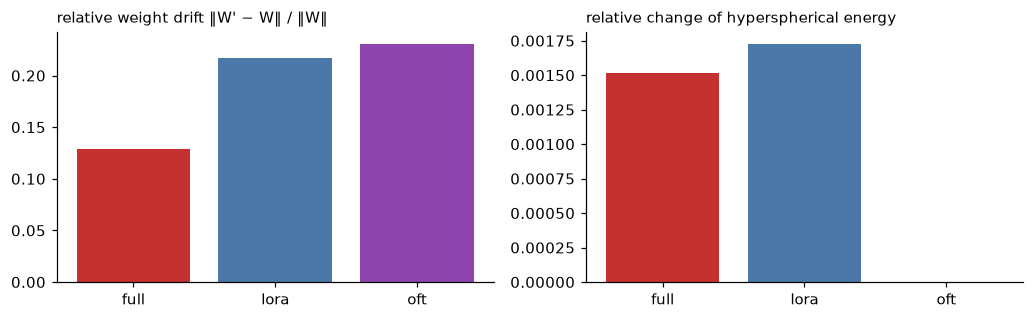

drift: {'full': 0.1285, 'lora': 0.217, 'oft': 0.2308} | HE change: {'full': 0.00152, 'lora': 0.00173, 'oft': 1.01e-08}


In [8]:
def attention_weights(model):
    out = {}
    for li, layer in enumerate(model.vlm.layers):
        for name in ("q", "k", "v", "o"):
            mod = getattr(layer, name)
            out[f"L{li}.{name}"] = (mod.merged_weight() if hasattr(mod, "merged_weight") else mod.weight).detach()
    return out
ref = attention_weights(source)
drift, energy = {}, {}
for method in ("full", "lora", "oft"):
    w = attention_weights(adapted[(method, 5e-4)])
    drift[method] = np.mean([float((w[k] - ref[k]).norm() / ref[k].norm()) for k in ref])
    energy[method] = np.mean([abs(hyperspherical_energy(w[k]) - hyperspherical_energy(ref[k])) / hyperspherical_energy(ref[k]) for k in ref])
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.0))
axes[0].bar(list(drift), list(drift.values()), color=[colours[m] for m in drift]); axes[0].set_title("relative weight drift ‖W' − W‖ / ‖W‖", fontsize=10, loc="left")
axes[1].bar(list(energy), list(energy.values()), color=[colours[m] for m in energy]); axes[1].set_title("relative change of hyperspherical energy", fontsize=10, loc="left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("drift:", {k: round(float(v), 4) for k, v in drift.items()}, "| HE change:", {k: float(f"{v:.2e}") for k, v in energy.items()})

The **amount** the weights move is similar for the three methods (relative drift ≈ 0.13 for full fine-tuning, ≈ 0.22 for LoRA and OFT at the same learning rate: adapters have fewer parameters, so each moves further), so "how far" is not what separates them. The **direction** is: OFT's hyperspherical-energy change is numerically zero (10⁻⁸, by construction), while full and LoRA changes are five orders of magnitude larger
(10⁻³, still tiny in absolute terms). So the angle-preservation property holds exactly; what Step 4 shows is that it is not what determines forgetting.

## Step 7: Choosing a method, and recap

| situation | choice | why |
|---|---|---|
| lots of data, lots of compute, a new robot with a different action space | **full fine-tuning** (small learning rate, replay if old skills matter) | most capacity; the best ceiling |
| limited data / compute; many tasks; want to keep one base and many small adapters | **LoRA** (all linear layers, rank 8-32) | ~1 % of the parameters; mergeable; tolerant of the learning rate |
| the base representation is already good; very little data | **frozen backbone + new head** | the backbone cannot forget, but the head can; learns only what the features already support |
| you care that the pre-trained *geometry* is preserved (e.g. text-to-image personalisation) | **OFT** | exact angle preservation; evidence for robot policies is thin |
| you want fast *inference* and success on a benchmark with a pre-trained VLA | **OpenVLA-OFT recipe** | parallel decoding + chunking + continuous L1 head (not orthogonal) |

**Take-aways.** (1) LoRA adds a trainable low-rank `B A`, starts as the identity and merges for free; OFT multiplies by a learned orthogonal rotation (Cayley parametrisation) and exactly preserves neuron angles. (2) *OpenVLA-OFT is a recipe, not a parameterisation.* (3) At a well-tuned learning rate, full fine-tuning, LoRA and OFT learn and forget about the same; adapters make training
**more forgiving** of a too-large learning rate. (4) Freezing the backbone caps what can be learned and does *not* by itself prevent forgetting (the retrained head drifts). (5) **Replaying old data** beat every method, and is the thing to reach for first.

### 🧪 Exercises
1. Sweep the LoRA **rank** (1, 4, 16, 64): where does the new-colour success saturate? Compare to the rank of the *full* fine-tuning update (SVD of `W' − W`).
2. Add LoRA to the **MLP** layers (`gate`, `up`, `down`) as well (`inject_adapters(..., targets=("q", "k", "v", "o", "gate", "up", "down"))`): does it help the new colour?
3. Repeat Step 4 with **10** and **200** demonstrations. Which method benefits from more data?
4. Merge the LoRA adapters of two *different* new colours (e.g. blue and a fourth colour) by adding their updates: does the merged model do both?
5. Train OFT with a **larger block size** (16, 32): more parameters, a richer rotation; does forgetting change?